# NumCompute-Stream demo

A short tour of the streaming extension: a stream of data arrives **one chunk at a time**,
and the model learns from each chunk without ever seeing the whole dataset at once.

1. A stream whose rule changes halfway (drift)
2. The buffered decision tree
3. A pipeline run by `StreamTrainer` (test, then train)
4. Plots
5. Comparing buffer sizes

## Setup

In [20]:
import sys
from pathlib import Path

# find the repository folder, whether the notebook is run from it or from demo/
for folder in (Path.cwd(), Path.cwd().parent):
    if (folder / "numcompute_stream").is_dir():
        sys.path.insert(0, str(folder))
        break

import numpy as np

from numcompute_stream.pipeline import Pipeline
from numcompute_stream.preprocessing import StandardScaler
from numcompute_stream.stream import StreamTrainer
from numcompute_stream.tree import DecisionTreeClassifier
from numcompute_stream.visualise import (compare_models, plot_metric_over_time,
                                         plot_predictions_vs_ground_truth)

## 1. A stream with drift

The data has 5 numeric features. The class is **1 when `x0 + x1 > 0`** for the first 20 chunks.
From chunk 20 on, the rule changes to **`x0 - x1 > 0`**. This is *drift*: what the model learned
early on stops being true. Also, 5% of the labels are flipped at random, so no model can be perfect.

In [21]:
N_CHUNKS, CHUNK_ROWS, DRIFT_CHUNK = 40, 50, 20

def make_stream(seed=0):
    rng = np.random.default_rng(seed)
    chunks = []
    for chunk in range(N_CHUNKS):
        X = rng.normal(size=(CHUNK_ROWS, 5))
        signal = X[:, 0] + X[:, 1] if chunk < DRIFT_CHUNK else X[:, 0] - X[:, 1]
        y = (signal > 0).astype(int)
        flip = rng.random(CHUNK_ROWS) < 0.05
        chunks.append((X, np.where(flip, 1 - y, y)))
    return chunks

stream = make_stream()
print(len(stream), "chunks of", stream[0][0].shape[0], "rows and", stream[0][0].shape[1], "features")

40 chunks of 50 rows and 5 features


## 2. The buffered decision tree

`partial_fit` does **not** retrain on every chunk. It adds the chunk to a buffer, and only when the
buffer holds at least `buffer_size` rows does it rebuild the tree on those rows and empty the buffer.
Between rebuilds, `predict` uses the latest tree. Before the first tree exists, it predicts the most
common label seen so far.

Here `buffer_size=100` and each chunk has 50 rows, so the tree is rebuilt every second chunk.
We ask the tree to predict the same point after every chunk.

In [22]:
tree = DecisionTreeClassifier(max_depth=3, buffer_size=100, random_state=0)
point = np.array([[1.0, 1.0, 0.0, 0.0, 0.0]])        # x0 + x1 > 0, so the true class is 1

print("chunk  tree rebuilt?  nodes  prediction for the point")
for number, (X, y) in enumerate(stream[:6]):
    before = getattr(tree, "feature_", None)
    tree.partial_fit(X, y)
    rebuilt = getattr(tree, "feature_", None) is not before
    nodes = getattr(tree, "n_nodes_", "-")
    print(f"{number:>5}  {'yes' if rebuilt else 'no':<13}  {nodes!s:>5}  {tree.predict(point)[0]}")

chunk  tree rebuilt?  nodes  prediction for the point
    0  no                 -  0
    1  yes               13  1
    2  no                13  1
    3  yes               15  1
    4  no                15  1
    5  yes               13  1


## 3. Pipeline and `StreamTrainer`

The pipeline scales the features, then feeds the tree. `StreamTrainer` runs the usual streaming loop:

* `score_chunk`: predict the new chunk **first**, with a model that has never seen it, so the score is honest
* `fit_chunk`: only then learn from the chunk

It keeps one log row per chunk. `window=3` also gives a rolling accuracy over the last 3 chunks.

In [23]:
def run_stream(buffer_size, chunks=stream):
    pipe = Pipeline([("scale", StandardScaler()),
                     ("model", DecisionTreeClassifier(max_depth=5, buffer_size=buffer_size, random_state=0))])
    trainer = StreamTrainer(pipe, window=3)
    for X, y in chunks:
        trainer.score_chunk(X, y)     # test first
        trainer.fit_chunk(X, y)       # then train
    return trainer

trainer = run_stream(buffer_size=100)

print("chunk  accuracy  cumulative  fit ms  rebuilt  memory bytes")
for row in trainer.log[:8]:
    print(f"{row['chunk']:>5}  {row['accuracy']:>8.3f}  {row['cumulative_accuracy']:>10.3f}  "
          f"{row['fit_seconds'] * 1000:>6.2f}  {str(row['retrained']):<7}  {row['memory_bytes']:>12.0f}")

chunk  accuracy  cumulative  fit ms  rebuilt  memory bytes
    0       nan         nan    0.51  False            2440
    1     0.600       0.600    5.91  True              836
    2     0.860       0.730    0.20  False            3036
    3     0.800       0.753    5.55  True             1004
    4     0.860       0.780    0.28  False            3204
    5     0.840       0.792    8.19  True              948
    6     0.880       0.807    0.50  False            3148
    7     0.820       0.809    9.71  True             1004


The first chunk has no accuracy (`nan`): nothing has been learned yet, so there is nothing to test.
Chunks where the tree is rebuilt take longer to fit, and the memory drops right after a rebuild, because the buffer is emptied.

## 4. Plots

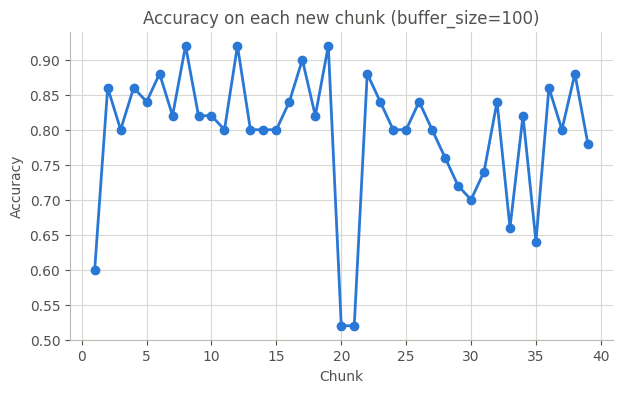

In [24]:
accuracy = [row["accuracy"] for row in trainer.log]
_ = plot_metric_over_time(accuracy, "Accuracy on each new chunk (buffer_size=100)", "Accuracy")

The dip just after chunk 20 is the drift: the tree has to be rebuilt on new data before it catches up.

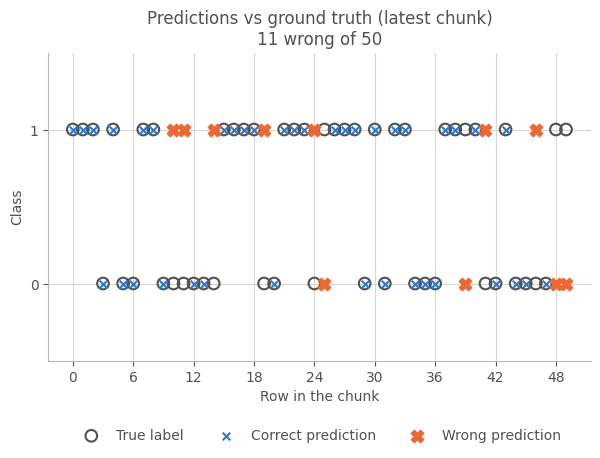

In [25]:
_ = plot_predictions_vs_ground_truth(trainer.last_y_true, trainer.last_y_pred)

Predictions against the true labels on the latest chunk. Each wrong prediction is an orange cross away from its circle.

## 5. Different buffer sizes

A small buffer rebuilds often and reacts quickly, but each tree sees little data. A large buffer sees more data per
rebuild, but it waits longer for the first tree, adapts slowly after the drift, and holds more memory.

In [26]:
BUFFER_SIZES = (50, 100, 250, 500, 1000)
results = {size: run_stream(size) for size in BUFFER_SIZES}

print("buffer_size  rebuilds  accuracy before drift  accuracy after drift  peak memory KB")
for size, t in results.items():
    acc = np.array([row["accuracy"] for row in t.log])
    rebuilds = sum(row["retrained"] for row in t.log)
    peak = max(row["memory_bytes"] for row in t.log) / 1024
    print(f"{size:>11}  {rebuilds:>8}  {np.nanmean(acc[:DRIFT_CHUNK]):>21.3f}  "
          f"{np.nanmean(acc[DRIFT_CHUNK:]):>20.3f}  {peak:>14.1f}")

buffer_size  rebuilds  accuracy before drift  accuracy after drift  peak memory KB
         50        40                  0.783                 0.751             0.9
        100        20                  0.833                 0.760             3.2
        250         8                  0.778                 0.778            10.0
        500         4                  0.692                 0.706            21.1
       1000         2                  0.500                 0.521            42.5


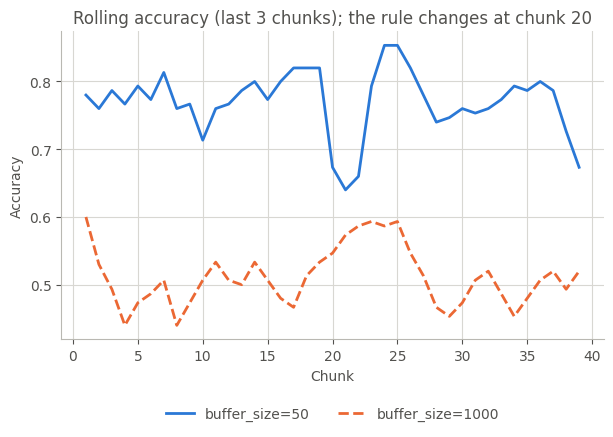

In [27]:
small, large = BUFFER_SIZES[0], BUFFER_SIZES[-1]
_ = compare_models([row["rolling_accuracy"] for row in results[small].log],
                   [row["rolling_accuracy"] for row in results[large].log],
                   (f"buffer_size={small}", f"buffer_size={large}"),
                   title=f"Rolling accuracy (last 3 chunks); the rule changes at chunk {DRIFT_CHUNK}",
                   ylabel="Accuracy")

## Summary

* The tree learns from a stream with a **buffer**: it rebuilds only when the buffer is full, so it never needs the whole dataset.
* `buffer_size` is a trade-off between reacting quickly (small) and seeing more data per tree (large), at a cost in time and memory.
* `StreamTrainer` tests each chunk *before* learning from it, so the accuracy it logs is an honest estimate, and it records
  time and memory for every chunk.
* The numbers come from one synthetic stream with a controlled drift, so they show the behaviour, not a general result.